# Freight-rate EDA

Analysis of `data/train-test.csv` for predicting `posted_rate`. The supplied validation set covers a later period (November–December 2025), so validation should respect time order.

In [24]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import random 
random.seed(42)


ROOT = Path.cwd()
if not (ROOT / 'data').exists():
    ROOT = Path.cwd().parents[1]

tt_df = pd.read_csv(ROOT / 'data/train-test.csv', parse_dates=['date'])
validation = pd.read_csv(ROOT / 'data/validation.csv', parse_dates=['date'])
for df in (tt_df, validation):
    df['route'] = df['pickup'] + ' → ' + df['delivery']
tt_df['rate_per_mile'] = tt_df['posted_rate'] / tt_df['distance']
print(f'Train: {tt_df.shape}; validation: {validation.shape}')
display(tt_df.head())

Train: (48000, 16); validation: (12000, 14)


,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,posted_rate,route,rate_per_mile
0,TR-000001,Richmond,Baltimore,38.09122,-76.78906,38.16908,-72.74564,274.3,Dry Van,30658.0,2025-01-01,0.95684,2.39595,645.41,Richmond → Baltimore,2.352935
1,TR-000002,Richmond,Philadelphia,38.09122,-76.78906,39.22317,-72.96710,280.5,Reefer,17555.0,2025-01-01,0.97623,2.43355,679.97,Richmond → Philadelphia,2.424135
2,TR-000003,Philadelphia,Green Bay,39.22317,-72.96710,44.30296,-87.52871,967.8,Dry Van,31721.0,2025-01-01,1.00971,1.84491,1802.54,Philadelphia → Green Bay,1.862513
3,TR-000004,Hartford,Atlanta,39.55328,-72.18051,34.84933,-86.28940,965.4,Dry Van,32333.0,2025-01-01,0.94518,1.87712,1827.28,Hartford → Atlanta,1.892770
4,TR-000005,Dallas,Nashville,31.83025,-94.38343,35.29479,-88.08915,541.9,Reefer,35183.0,2025-01-01,0.98480,2.56300,1380.28,Dallas → Nashville,2.547112


In [25]:
pd.DataFrame(tt_df.isna().sum(), columns=['missing']).sort_values('missing', ascending=False)

,missing
market_index,374
weight,300
load_id,0
pickup,0
pickup_lon,0
delivery_lat,0
delivery,0
pickup_lat,0
distance,0
delivery_lon,0


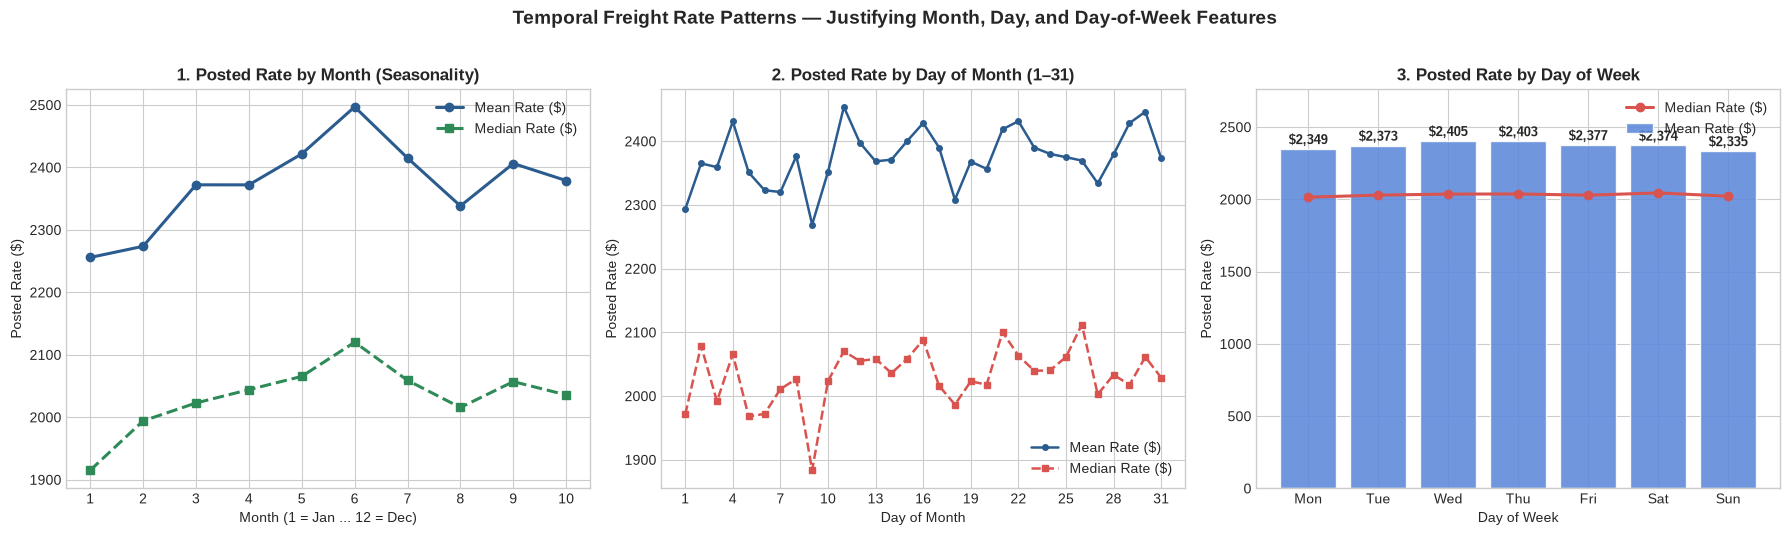

In [26]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.style.use('seaborn-v0_8-whitegrid')  # Remove this line if using an older matplotlib version

# Use train_raw so EDA stays strictly on the training split
eda_time = tt_df.copy()
dt = pd.to_datetime(eda_time['date'])
eda_time['month'] = dt.dt.month
eda_time['day'] = dt.dt.day
eda_time['dayofweek'] = dt.dt.dayofweek  # 0=Mon, 6=Sun

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 5.2))
fig.suptitle("Temporal Freight Rate Patterns — Justifying Month, Day, and Day-of-Week Features",
             fontsize=14, fontweight='bold', y=1.02)

# --- PLOT 1: Posted Rate vs. Month (Seasonal Freight Cycles) ---
month_stats = eda_time.groupby('month')['posted_rate'].agg(['mean', 'median'])
ax1.plot(month_stats.index, month_stats['mean'], marker='o', linewidth=2.2, color='#2b5c8f', label='Mean Rate ($)')
ax1.plot(month_stats.index, month_stats['median'], marker='s', linewidth=2.2, linestyle='--', color='#2e8b57', label='Median Rate ($)')
ax1.set_title("1. Posted Rate by Month (Seasonality)", fontweight='bold')
ax1.set_xlabel("Month (1 = Jan ... 12 = Dec)")
ax1.set_ylabel("Posted Rate ($)")
ax1.set_xticks(month_stats.index)
ax1.legend()

# --- PLOT 2: Posted Rate vs. Day of Month (End-of-Month Shipping Surge) ---
day_stats = eda_time.groupby('day')['posted_rate'].agg(['mean', 'median'])
ax2.plot(day_stats.index, day_stats['mean'], marker='o', markersize=4, linewidth=1.8, color='#2b5c8f', label='Mean Rate ($)')
ax2.plot(day_stats.index, day_stats['median'], marker='s', markersize=4, linewidth=1.8, linestyle='--', color='#d9534f', label='Median Rate ($)')
ax2.set_title("2. Posted Rate by Day of Month (1–31)", fontweight='bold')
ax2.set_xlabel("Day of Month")
ax2.set_ylabel("Posted Rate ($)")
ax2.set_xticks(range(1, 32, 3))
ax2.legend()

# --- PLOT 3: Posted Rate vs. Day of Week (Weekly Capacity Cycle) ---
dow_names = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
dow_stats = eda_time.groupby('dayofweek')['posted_rate'].agg(['mean', 'median']).reindex(range(7))

x_pos = np.arange(len(dow_names))
bars = ax3.bar(x_pos, dow_stats['mean'], color='#5c88da', edgecolor='white', alpha=0.88, label='Mean Rate ($)')
ax3.plot(x_pos, dow_stats['median'], color='#d9534f', marker='o', linewidth=2.2, label='Median Rate ($)')

# Annotate exact mean dollar value above each day bar
for bar in bars:
    h = bar.get_height()
    if not np.isnan(h):
        ax3.text(bar.get_x() + bar.get_width() / 2.0, h + 15, f"${h:,.0f}",
                 ha='center', va='bottom', fontsize=9, fontweight='bold')

ax3.set_title("3. Posted Rate by Day of Week", fontweight='bold')
ax3.set_xlabel("Day of Week")
ax3.set_ylabel("Posted Rate ($)")
ax3.set_xticks(x_pos)
ax3.set_xticklabels(dow_names)
ax3.set_ylim(0, dow_stats['mean'].max() * 1.15)
ax3.legend()

plt.tight_layout()
plt.show()


### Temporal Feature Analysis (`month`, `day`, `dayofweek`)

* **Strong Macro-Seasonality (`month`):** The monthly plot reveals a clear seasonal trend—mean rates rise steadily from **~$2,256 in January to a peak of ~$2,496 in June** (+10.6%) before moderating in Q3. This confirms `pickup_month` is an essential feature for capturing broader market shifts.
* **Subtle Intra-Month & Weekly Variance (`day` & `dayofweek`):** Across the day-of-month (Days 1–31) and day-of-week (Mon–Sun) plots, marginal averages remain relatively stable—with weekday means varying within a narrow **$70 window ($2,335 on Sunday to $2,405 on Wednesday, ~3%)**. Because raw rate averages are heavily dominated by trip distance, standalone calendar effects appear subtle in univariate plots.
* **Modeling Decision (Why We Still Retain `day` and `dayofweek`):** Rather than discarding `day` and `dayofweek` based solely on univariate marginal plots, we retain them so our models can capture **conditional interactions** (e.g., end-of-month shipping surges or Friday capacity tightening on specific lanes/equipment) while relying on **L1/L2 regularization (`ElasticNet`)** and tree minimum-leaf constraints (`min_child_samples`) to automatically shrink their weights if they add noise.


In [27]:
req_df = tt_df.drop(columns=['load_id', 'pickup', 'delivery', 'route', 'rate_per_mile'])
clean_df = req_df.loc[req_df['weight'].notnull() & req_df['market_index'].notnull()]
clean_df2 = clean_df.loc[(clean_df['weight']>0) & (clean_df['distance']>0)]
clean_df3 = clean_df2.drop_duplicates().reset_index(drop=True)
print(clean_df3.shape[0], clean_df2.shape[0], clean_df.shape[0], req_df.shape[0], tt_df.shape[0])

47038 47038 47327 48000 48000


In [28]:
def preprocess(df1: pd.DataFrame, encode: bool = False):
    df = df1.copy()
    dt = pd.to_datetime(df['date'])
    df['pickup_day'] = dt.dt.day
    df['pickup_month'] = dt.dt.month
    # df['pickup_dayofweek'] = dt.dt.dayofweek
    df = df.drop(columns=['date'])

    cat_cols = df.select_dtypes(include=['object', 'category']).columns.tolist()
    df2 = pd.get_dummies(df, columns=cat_cols, drop_first=True, dtype=int)

    if encode:
        return df2
    else:
        return df

In [29]:
clean_df3['date'] = pd.to_datetime(clean_df3['date'])
clean_df3 = clean_df3.sort_values('date').reset_index(drop=True)

split_index = int(clean_df3.shape[0] * 0.8)
train_raw = clean_df3.iloc[:split_index]
test_raw = clean_df3.iloc[split_index:]

train_encoded_df = preprocess(train_raw, encode=True)
test_encoded_df = preprocess(test_raw, encode=True)

train_df = preprocess(train_raw, encode=False)
test_df = preprocess(test_raw, encode=False)

In [31]:
train_raw.to_csv(ROOT / 'data/cleaned_raw_train.csv', index=False)
test_raw.to_csv(ROOT / 'data/cleaned_raw_test.csv', index=False)
train_encoded_df.to_csv(ROOT / 'data/cleaned_train_encoded.csv', index=False)
test_encoded_df.to_csv(ROOT / 'data/cleaned_test_encoded.csv', index=False)
train_df.to_csv(ROOT / 'data/cleaned_train.csv', index=False)
test_df.to_csv(ROOT / 'data/cleaned_test.csv', index=False)